In [2]:
from bai_utils import *
from weights_utils import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns

from sklearn.preprocessing import normalize
from collections import defaultdict

In [21]:
best_list_1 = defaultdict(list)
tau_list_1 = defaultdict(list)
alpha_hist_list_1 = []

best_list_2 = defaultdict(list)
tau_list_2 = defaultdict(list)
alpha_hist_list_2 = []

for delta in np.linspace(0.001,.01,10):
    for i in trange(1000):

        m = 2
        #mu = np.random.rand(m)*10
        mu = np.random.choice(m, size=m, replace=False)#np.arange(m)

        prob_dict = {
                "m": m,
                "mu": mu,
              }

        prob = gauss_discover(**prob_dict)
        solver = track_n_stop_solver(prob)
        #reg, rwd, best, tau = solver.run(T)[:2]
        reg, rwd, best, tau = solver.run(1000, delta)
        best_list_1[delta].append(best == np.argmax(mu))
        tau_list_1[delta].append(tau)
        #alpha_hist_list_1.append(solver.alpha_hist)

        prob = gauss_discover(**prob_dict)
        solver = sample_track_n_stop_solver(prob)
        reg, rwd, best, tau = solver.run(1000, delta)

        best_list_2[delta].append(best == np.argmax(mu))
        tau_list_2[delta].append(tau)
        #alpha_hist_list_2.append(solver.alpha_hist)

100%|███████████████████████████████████████| 1000/1000 [00:19<00:00, 52.15it/s]


In [41]:
pd.concat({'track_n_stop_tau':pd.DataFrame(tau_list_1).mean(),
           'track_n_stop_tau_std':pd.DataFrame(tau_list_1).std()/(1000**.5),
           'sample_track_n_stop_tau':pd.DataFrame(tau_list_2).mean(),
           'sample_track_n_stop_tau_std':pd.DataFrame(tau_list_2).std()/(1000**.5),
           'track_n_stop_correct':pd.DataFrame(best_list_1).mean(),
           'sample_track_n_stop_correct':pd.DataFrame(best_list_2).mean()
          }, 1)

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_3471/322829407.py:1: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  pd.concat({'track_n_stop_tau':pd.DataFrame(tau_list_1).mean(),


,track_n_stop_tau,track_n_stop_tau_std,sample_track_n_stop_tau,sample_track_n_stop_tau_std,track_n_stop_correct,sample_track_n_stop_correct
0.001,35.530,0.803988,34.223,0.778804,1.000,0.998
0.002,32.147,0.741464,31.876,0.746207,0.999,0.997
0.003,29.340,0.711590,30.275,0.766162,0.998,0.999
0.004,28.666,0.708750,28.787,0.744954,0.999,0.999
0.005,27.409,0.687338,28.691,0.727557,0.999,0.995
0.006,26.736,0.670050,26.914,0.716919,0.999,0.999
0.007,26.998,0.691355,27.357,0.705011,0.999,0.998
0.008,25.671,0.691150,26.483,0.685143,0.998,0.999
0.009,24.538,0.616728,25.846,0.706455,0.999,0.994
0.010,25.105,0.686695,26.572,0.698271,0.997,0.992


In [42]:
plt.plot([np.log(((x-alpha_hist_list_1[0][-1]) ** 2).sum()) for x in alpha_hist_list_1[0][:-1]], label='track')
plt.plot([np.log(((x-alpha_hist_list_2[0][-1]) ** 2).sum()) for x in alpha_hist_list_2[0][:-1]], label='sample')
plt.legend()

IndexError: list index out of range

In [11]:
prob = gauss_discover(**prob_dict)

t_max = 1000
t_array = np.arange(t_max)+1.001
delta = 0.1
beta = m * np.log(np.log(t_array)) + np.log(1/delta)
z_list = []

for t in range(m):
    r, _ = prob.take_action(t)
    
#T = pd.DataFrame({'action':prob.actions, 'T':1}).groupby('action').sum()['T'].to_numpy()

#for t in trange(m, 1000):
Z = 0
t = m
while Z < beta[t]:
    
    #df = pd.DataFrame({'action':prob.actions, 'T':1, 'reward':prob.rewards}) 
    #T = df.groupby('action').sum()['T'].to_numpy()
    #mu_hat = df.groupby('action').mean()['reward'].to_numpy()
    T = prob.T
    mu_hat = prob.mean_hat
    i_star = np.argmax(mu_hat)
        
    if np.min(T) < np.sqrt(t):
        #T = pd.DataFrame({'action':prob.actions, 'T':1, 'reward':prob.rewards}).groupby('action').sum()['T'].to_numpy()
        action = np.argmin(T)
        
    else:
        y_star = solver_F(mu_hat)
        alpha_star = (np.array([x(mu_hat[i_star], mu_hat[a], y_star) for a in range(m)]) / 
                      np.sum([x(mu_hat[i_star], mu_hat[a], y_star) for a in range(m)]))
        action = np.argmax(t*alpha_star - T)
        
    z = []
    for a in np.setdiff1d(range(m), i_star):
        mu_prime = mu_hat.copy()
        mu_prime[a] = mu_hat.max()
        z.append(sum(T * np.power(mu_prime - mu_hat, 2)) / 2)
    
    Z = min(z)
    z_list.append(Z)
    t = t + 1
        
    r, _ = prob.take_action(action)
    

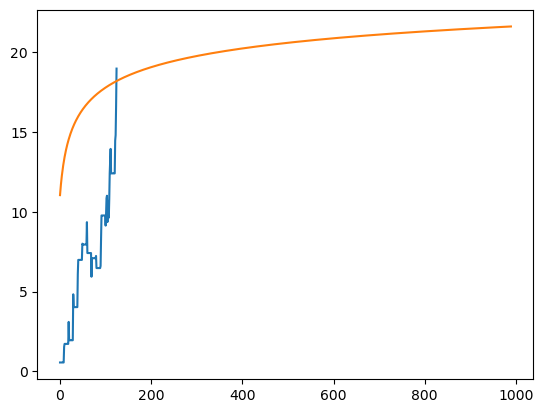

In [15]:
delta = .1
#t = np.arange(1000)+1.001
#beta = m * np.log(np.log(t)) + np.log(1/delta)

plt.plot(z_list)
plt.plot(beta[m:])
#plt.vlines(np.where(beta[m:t] - z_list < 0)[0][0],0, np.max(z_list), color='r')

In [6]:
def d_gauss(mu1, mu2):
    return ((mu1 - mu2) ** 2) / 2

def I(mu1, mu2, alpha):
    return alpha * d_gauss(mu1, alpha * mu1 + (1-alpha) * mu2) + (1 - alpha) * d_gauss(mu2, alpha * mu1 + (1-alpha) * mu2)

def g(mu1, mua, x):
    return (1 + x) * I(mu1, mua, 1 / (1 + x))
    
def x(mu1, mua, y):
    x1 = 0
    x2 = 1000
    if mu1 == mua:
        return 1
    
    x_mid = (x1 + x2) / 2
    #i = 0
    while abs(g(mu1, mua, x_mid) - y) > 1e-10:
        if g(mu1, mua, x_mid) > y:
            x2 = (x1 + x2) / 2
        else:
            x1 = (x1 + x2) / 2
        
        x_mid = (x1 + x2) / 2
        #i = i + 1
            
    return x_mid

def F(mu, y):
    m = mu.shape[0]
    y_max = (d_gauss(np.sort(mu)[-1],np.sort(mu)[-2]))
    if y > y_max:
        return 1e10
    i_star = np.argmax(mu)
    x_ = [x(mu[i_star], mu[a], y) for a in range(m)]
    return np.sum([(d_gauss(mu[i_star], (mu[i_star] + x_[a] * mu[a]) / (1 + x_[a])) / 
                    d_gauss(mu[a], (mu[i_star] + x_[a] * mu[a]) / (1 + x_[a]))) 
                   for a in np.setdiff1d(range(m), i_star)])
    
def solver_F(mu):
    
    y1 = 0
    y2 = d_gauss(np.sort(mu)[-1],np.sort(mu)[-2]) - 1e-10
    #ymax = (d_gauss(np.sort(mu)[-1],np.sort(mu)[-2]))
    y_mid = (y1 + y2) / 2
    i = 0
    while abs(F(mu, y_mid) - 1) > 1e-3 and i < 100:
        #print(F(mu, y_mid))
        if F(mu, y_mid) > 1:
            y2 = (y1 + y2) / 2
        else:
            y1 = (y1 + y2) / 2
        
        y_mid = (y1 + y2) / 2
        #print(F(mu, y_mid))
        i = i + 1
            
    return y_mid

def solver_alpha(mu):
    m = mu.shape[0]
    i_star = np.argmax(mu)
    y_star = solver_F(mu)
    alpha_star = (np.array([x(mu[i_star], mu[a], y_star) for a in range(m)]) / 
                  (np.sum([x(mu[i_star], mu[a], y_star) for a in range(m)])))
    return alpha_star
